# Sentinel-3 OLCI coastal water-quality pipeline 

From raw monthly Sentinel-3 OLCI reflectance to annual water-quality time series for the mine area, for one mining asset (Weda Bay Nickel / IWIP, North Maluku).

**Why these indicators.** The indicators are chosen within the Planetary Boundaries framework (Richardson et al., 2023), using the five water sub-boundaries of Gleeson et al. (2020). Two axes structure the selection:
* **Hydrosphere vs biosphere** — the water itself (blue) vs the vegetation that depends on it (green).
* **Quantity/availability vs quality** — how much water there is vs what state it is in.

On land, surface-water extent, canopy moisture and evapotranspiration cover the quantity side. In the coastal water, **turbidity / light attenuation** (Kd490, Turbidity) and **chlorophyll-a** (NDCI) cover the quality side. This notebook handles the coastal water-quality indicators.

![Indicator framework](https://raw.githubusercontent.com/Hauzero/Bridge-SpatialSustainableFinance/main/notebooks/images/indicator_framework.png)

*Figure 1: Indicator selection is embedded in the Planetary Boundaries framework (Richardson et al., 2023) and Gleeson et al. (2020)'s water sub-boundaries, proceeding along two axes of biosphere–hydrosphere and quantity–quality to capture broad dimensions relevant to mining-affected coastal zones spanning blue (water) and green (vegetation) systems.*

| Step | What happens |
|---|---|
| 1 · ROI selection | mine 10 km buffer (treatment) + 50 km search area → download bounding box |
| 2 · S-3 downloader | CMEMS OLCI L4 monthly Rrs via `copernicusmarine` (optional — cached files are reused) |
| 3 · Quality check | count non-physical **negative** Rrs per band |
| 4 · Gap filling | negatives → missing → temporal infill → floor; annual composites from valid observations |
| 5 · Indicator retrieval | Kd490 (Mueller-type), NDCI (Mishra & Mishra 2012), Turbidity (Ouillon et al. 2008) |
| 6 · Time series | treatment area, annual mean ± 0.5σ |

**Data note.** Product `cmems_obs-oc_glo_bgc-reflectance_my_l4-olci-300m_P1M` is **L4** (CMEMS already fills cloud gaps) and **monthly**. It is delivered on a 1/180° grid (~600 m at the equator) and it is corrected to be **water-leaving** reflectance.

This notebook condenses the research scripts behind the workshop results into one pipeline. It covers the coastal water domain only; the terrestrial water indicators and the counterfactual comparison are not included here.

## 0 · Setup
Paths, study site, gap-filling and analysis settings. The product, bands and period are set in step 2.

In [ ]:
# Google Colab: fetch the repository so that data/ is available (does nothing when run locally)
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.isdir("data"):
    subprocess.run(["git", "clone", "https://github.com/Hauzero/Bridge-SpatialSustainableFinance.git"], check=True)
    os.chdir("Bridge-SpatialSustainableFinance/notebooks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas", "rasterio", "xarray", "netCDF4", "copernicusmarine"], check=True)


In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize, ListedColormap
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---- paths ----
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "rrs_monthly"       # monthly CMEMS files (not in the repository, see README)
DL_DIR  = RAW_DIR                             # the downloader (step 2) fills the same folder
OUT_DIR = ROOT / "outputs"

# ---- study site: Weda Bay Nickel / IWIP ----
MINE_LAT, MINE_LON = 0.471148, 127.943999   # asset location
TREAT_RADIUS_KM  = 10                       # treatment area = buffer around the mine
SEARCH_RADIUS_KM = 50                       # search area (download box; future counterfactuals)

# ---- gap filling ----
FLOOR_PCTL_MILD, FLOOR_PCTL_SEVERE = 1.0, 0.01   # floor percentiles for barely / strongly negative readings
SEVERITY_CLIP_PCTL = (1, 99)

# ---- analysis ----
BLOCKS = [("Baseline", 2016, 2019, "#c8e6c9"),
          ("Transition", 2020, 2022, "#fff9c4"),
          ("Recent", 2023, 2025, "#ffcdd2")]

OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1 · ROI selection
Both areas are circles around the mine coordinates from **Setup**, drawn in metres (UTM zone 52N):
* **Treatment** — `TREAT_RADIUS_KM` (10 km) around the mine.
* **Search area** — `SEARCH_RADIUS_KM` (50 km) around the mine; the counterfactual points come from here.
* **Download box** — the bounding box of the search area, so every pixel we need gets downloaded once.

The circles still contain land. Land is removed after loading: pixels with no value in any month are land.

{'lon_min': 127.475, 'lon_max': 128.413, 'lat_min': -0.001, 'lat_max': 0.943}


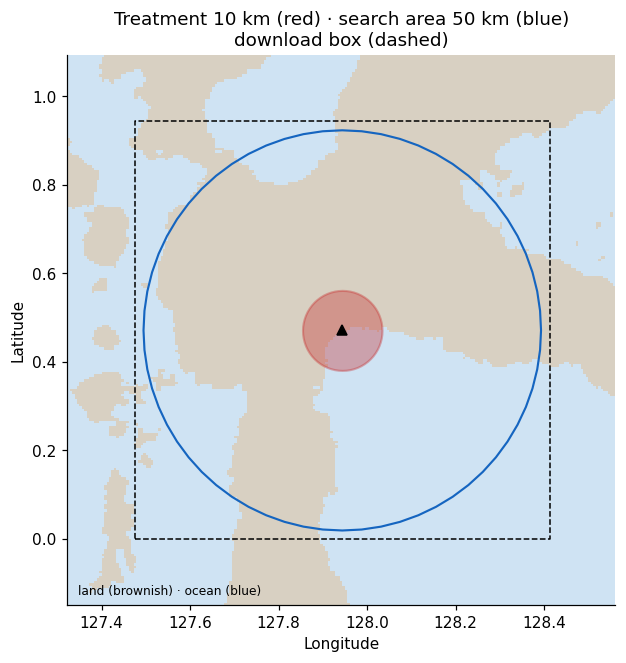

In [2]:
UTM = "EPSG:32652"   # metric CRS so the buffers are true kilometres (UTM zone 52N covers Halmahera)
site = gpd.GeoSeries(gpd.points_from_xy([MINE_LON], [MINE_LAT]), crs="EPSG:4326").to_crs(UTM)
mine_geom   = site.buffer(TREAT_RADIUS_KM * 1000).to_crs("EPSG:4326").iloc[0]
search_geom = site.buffer(SEARCH_RADIUS_KM * 1000).to_crs("EPSG:4326").iloc[0]

pad = 0.02
x0, y0, x1, y1 = search_geom.bounds
x0, y0, x1, y1 = x0 - pad, y0 - pad, x1 + pad, y1 + pad
BBOX = dict(lon_min=x0, lon_max=x1, lat_min=y0, lat_max=y1)
print({k: round(v, 3) for k, v in BBOX.items()})

# background: land / ocean from one existing monthly file (no value = land)
ref = sorted(RAW_DIR.glob("east_indonesia_*_rrs.nc"))
fig, ax = plt.subplots(figsize=(7, 6.5))
if ref:
    with xr.open_dataset(ref[len(ref) // 2]) as ds:
        bg = ds["RRS490"].isel(time=0).sel(longitude=slice(x0 - 0.15, x1 + 0.15),
                                           latitude=slice(y0 - 0.15, y1 + 0.15)).load()
    ax.pcolormesh(bg.longitude, bg.latitude, bg.notnull().astype(float),
                  cmap=ListedColormap(["#d8d0c2", "#cfe3f3"]), vmin=0, vmax=1, shading="nearest")
    ax.text(0.02, 0.02, "land (brownish) · ocean (blue)", transform=ax.transAxes, fontsize=8)
gpd.GeoSeries([search_geom]).plot(ax=ax, facecolor="none", edgecolor="#1565c0", lw=1.4)
gpd.GeoSeries([mine_geom]).plot(ax=ax, color="#c62828", alpha=0.35, edgecolor="#c62828", lw=1.4)
ax.plot(MINE_LON, MINE_LAT, "k^", ms=7)
ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], "k--", lw=1)
ax.set_title(f"Treatment {TREAT_RADIUS_KM} km (red) · search area {SEARCH_RADIUS_KM} km (blue)\ndownload box (dashed)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect("equal")
plt.show()

## 2 · Sentinel-3 OLCI downloader
Downloads one NetCDF per month for the download box from the Copernicus Marine Service (CMEMS): Sentinel-3 OLCI water-leaving reflectance, product `cmems_obs-oc_glo_bgc-reflectance_my_l4-olci-300m_P1M`.

**Account.** The download needs a free Copernicus Marine account and a one-time `copernicusmarine login` on the machine that runs the notebook. Step-by-step instructions: [`docs/copernicus_marine.md`](../docs/copernicus_marine.md).

**First run.** `data/rrs_monthly/` is empty in the repository, so `DOWNLOAD` switches on automatically and fetches all months (117 files, about 2 GB; minutes to an hour depending on the connection). Months already on disk are skipped, so an interrupted download can simply be restarted by re-running the cell. If you already have the monthly files (for example from a colleague), copy them into `data/rrs_monthly/` and no account is needed. To save time in a live session, shorten `START` / `END` below; the annual composites and the figures then cover only that period.

In [3]:
# ---- product and period ----
DATASET_ID = "cmems_obs-oc_glo_bgc-reflectance_my_l4-olci-300m_P1M"
BANDS = ["RRS490", "RRS510", "RRS560", "RRS620", "RRS665", "RRS681", "RRS709"]   # what the 3 indicators need
START, END = "2016-04", "2025-12"
EXCLUDE_MONTHS = set()          # e.g. {"2017-09"} drops a month from the annual means
MONTHS = pd.period_range(START, END, freq="M")
print(f"{len(MONTHS)} months, {len(BANDS)} bands")

# download automatically when no monthly files are present yet (needs a free Copernicus Marine account, see below)
DOWNLOAD = not any(RAW_DIR.glob("east_indonesia_*_rrs.nc"))

def download_month(period, out_file):
    import copernicusmarine
    ds = copernicusmarine.open_dataset(
        dataset_id=DATASET_ID, variables=BANDS,
        minimum_longitude=BBOX["lon_min"], maximum_longitude=BBOX["lon_max"],
        minimum_latitude=BBOX["lat_min"], maximum_latitude=BBOX["lat_max"],
        start_datetime=f"{period}-01", end_datetime=f"{period}-28")   # P1M stamps sit on the 1st
    ds.to_netcdf(out_file)
    ds.close()

if DOWNLOAD:
    DL_DIR.mkdir(parents=True, exist_ok=True)
    for p in MONTHS:
        f = DL_DIR / f"east_indonesia_{p.year}_{p.month:02d}_rrs.nc"
        if f.exists():
            continue
        try:
            download_month(p, f)
            print("downloaded", p)
        except Exception as e:
            print("failed", p, "-", e)
    SOURCE_DIR = DL_DIR
else:
    SOURCE_DIR = RAW_DIR
print("Reading monthly files from:", SOURCE_DIR)

117 months, 7 bands
Reading monthly files from: data/rrs_monthly


### Load the data
Stack the monthly files into one `(time, latitude, longitude)` cube and put the areas on its grid. Pixels with no value in any month are land, so `treat` keeps only the water pixels of the 10 km circle.

In [4]:
def load_cube(src_dir, months, bands, bbox):
    arrs, times = [], []
    for p in months:
        f = src_dir / f"east_indonesia_{p.year}_{p.month:02d}_rrs.nc"
        if not f.exists():
            print("missing", p); continue
        with xr.open_dataset(f) as ds:
            iy = np.where((ds.latitude >= bbox["lat_min"]) & (ds.latitude <= bbox["lat_max"]))[0]
            ix = np.where((ds.longitude >= bbox["lon_min"]) & (ds.longitude <= bbox["lon_max"]))[0]
            arrs.append(ds[bands].isel(time=0, latitude=iy, longitude=ix).drop_vars("time").load())
        times.append(p.to_timestamp())
    cube = xr.concat(arrs, dim=pd.Index(times, name="time"))
    return cube.sortby("latitude", ascending=False).astype("float32")   # north-up

cube = load_cube(SOURCE_DIR, MONTHS, BANDS, BBOX)

# grid: pixel size from the full coordinate span (a single float32 step is slightly off)
lat, lon = cube.latitude.values.astype("float64"), cube.longitude.values.astype("float64")
RES, RES_Y = (lon[-1] - lon[0]) / (lon.size - 1), (lat[0] - lat[-1]) / (lat.size - 1)
SHAPE = (lat.size, lon.size)
TRANSFORM = from_origin(lon[0] - RES / 2, lat[0] + RES_Y / 2, RES, RES_Y)
EXTENT = [lon.min() - RES / 2, lon.max() + RES / 2, lat.min() - RES_Y / 2, lat.max() + RES_Y / 2]

def on_grid(arr):
    return xr.DataArray(arr, dims=("latitude", "longitude"),
                        coords={"latitude": cube.latitude, "longitude": cube.longitude})

water = on_grid(cube["RRS490"].notnull().any("time").values)          # never observed = land
circle = on_grid(~geometry_mask([mine_geom.__geo_interface__], out_shape=SHAPE,
                                transform=TRANSFORM, all_touched=True))
treat = circle & water

print(f"cube {dict(cube.sizes)} | 10 km circle: {int(circle.sum())} px, "
      f"of which water (treatment): {int(treat.sum())}")

cube {'time': 117, 'latitude': 170, 'longitude': 169} | 10 km circle: 892 px, of which water (treatment): 337


## 3 · Raw reflectance — treatment area
Median monthly remote-sensing reflectance (Rrs) per band over the treatment water pixels; shading is the 25th–75th percentile.

**Why can water-leaving reflectance be negative?** The satellite measures all light leaving the top of the atmosphere, and over water most of it, typically around 90%, was scattered by air molecules and aerosols and never came out of the water. Atmospheric correction subtracts that atmospheric part, and what remains is Rrs. In the red and near-infrared, water absorbs almost all light, so the true water-leaving signal is close to zero and smaller than the uncertainty of what was subtracted: aerosol type and amount, residual sun glint, and, near coasts, light reflected from adjacent land. When the atmosphere is slightly over-estimated, the remainder drops below zero. A negative Rrs is therefore not a physical reflectance but a near-zero signal plus a correction error. That is why the blue–green bands, with a strong water signal, are clean, while 620–709 nm sit below zero most of the time.

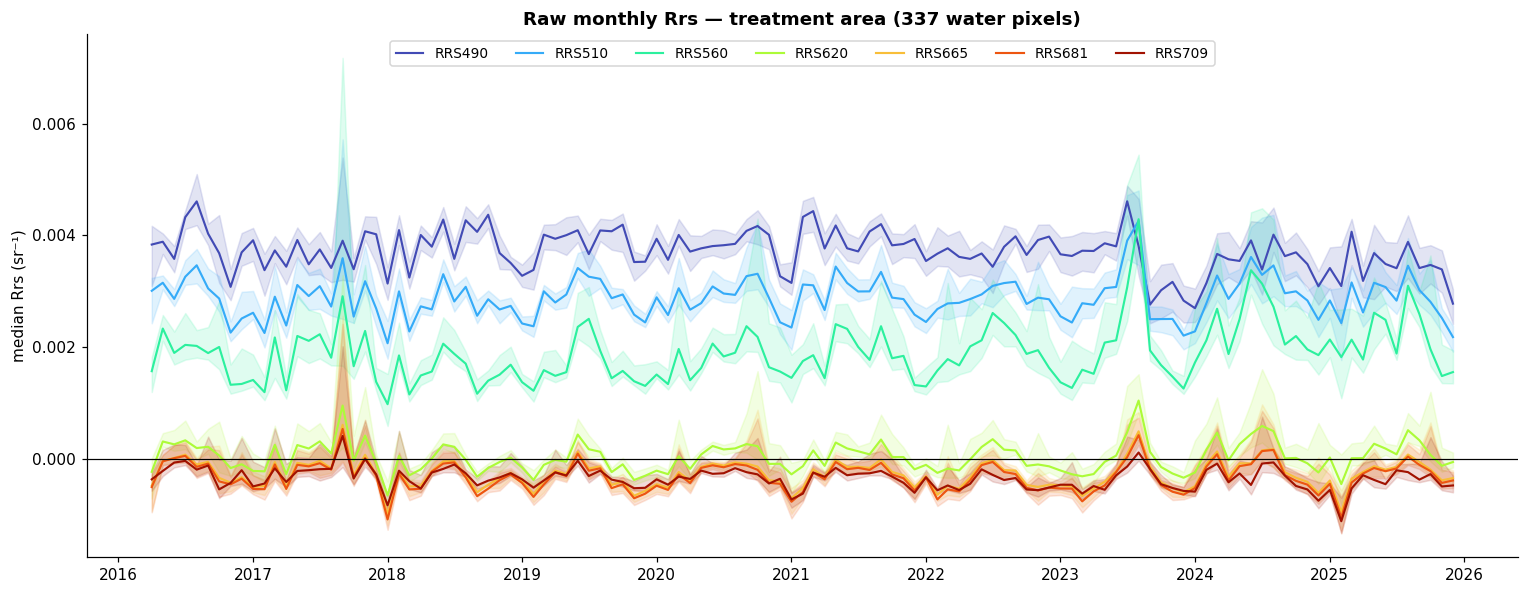

In [5]:
COLORS = dict(zip(BANDS, plt.cm.turbo(np.linspace(0.08, 0.95, len(BANDS)))))

def plot_rrs(ds, title, dim="time", ref=None):
    # median Rrs per band over the treatment pixels (shaded 25-75th pct); ref = dashed comparison
    fig, ax = plt.subplots(figsize=(14, 5.5))
    x = ds[dim]
    for b in BANDS:
        q = ds[b].where(treat).quantile([0.25, 0.5, 0.75], dim=["latitude", "longitude"])
        ax.fill_between(x, q.sel(quantile=0.25), q.sel(quantile=0.75), color=COLORS[b], alpha=0.15)
        ax.plot(x, q.sel(quantile=0.5), color=COLORS[b], lw=1.4, marker="o" if dim == "year" else None, label=b)
        if ref is not None:
            ax.plot(x, ref[b].where(treat).median(["latitude", "longitude"]), color=COLORS[b], lw=1, ls="--")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel("median Rrs (sr⁻¹)"); ax.legend(ncol=7, fontsize=9, loc="upper center")
    ax.set_title(f"{title} — treatment area ({int(treat.sum())} water pixels)", fontweight="bold")
    plt.tight_layout(); plt.show()

plot_rrs(cube, "Raw monthly Rrs")

## 4 · Gap filling
The goal is **one value per pixel and year, built from the best observations available**. Two parts:

**Monthly gap-filling (fallback).**
* **Good observations first.** A negative reading is not used as a value; it counts as missing. The gap is filled with the mean of the valid readings in the neighbouring months (±1, then ±2), then from the same month one year before and after.
* **Negative readings still count, but last.** Only where no valid neighbour exists, a small floor value is used: between the 1st and the 0.01th percentile of the band's own positive readings, lower the more negative the original reading was. A strongly negative reading says the true signal was very low; a barely negative one says it was just above zero.
* Land (never observed) stays empty.

**Annual composites.** Each pixel-year is the mean (and median) of that year's **valid observations only**. Gap-filled months are used only for pixel-years with no valid observation at all, so a year with two good months rests on those two months, not on ten filled ones.

In [6]:
def gapfill_band(da):
    raw = da.values
    missing = np.isnan(raw) | (raw < 0)                     # negatives count as missing
    clean = np.where(missing, np.nan, raw)
    land = np.isfinite(raw).sum(0) == 0
    filled = clean.copy()
    source = np.where(land[None], -1, np.where(missing, 4, 0))   # 0 valid, 1-3 neighbours, 4 floor, -1 land
    T = raw.shape[0]
    periods = pd.PeriodIndex(da.time.values, freq="M")
    pos = {p: i for i, p in enumerate(periods)}

    # 1-3: mean of valid neighbours, nearest first: ±1 month, ±2 months, ±1 year
    for t in range(T):
        todo = missing[t] & ~land
        for step, offs in enumerate(((-1, 1), (-2, 2), (-12, 12)), start=1):
            if not todo.any():
                break
            idx = [pos[periods[t] + o] for o in offs if periods[t] + o in pos]
            if idx:
                nm = np.nanmean(clean[idx], axis=0)
                ok = todo & np.isfinite(nm)
                filled[t][ok] = nm[ok]
                source[t][ok] = step
                todo &= ~ok

    # 4: still empty -> floor from the band's own positive values, lower for more negative readings
    still = np.isnan(filled) & ~land[None]
    neg = raw[raw < 0]
    if still.any():
        lo, hi = np.percentile(np.abs(neg), SEVERITY_CLIP_PCTL) if neg.size >= 5 else (0.0, 1.0)
        severity = np.where(still & (raw < 0), np.clip((np.abs(np.nan_to_num(raw)) - lo) / (hi - lo), 0, 1), 0.0)
        pctl = FLOOR_PCTL_MILD - severity * (FLOOR_PCTL_MILD - FLOOR_PCTL_SEVERE)
        grid = np.linspace(FLOOR_PCTL_SEVERE, FLOOR_PCTL_MILD, 101)
        filled = np.where(still, np.interp(pctl, grid, np.percentile(raw[~missing], grid)), filled)
    return da.copy(data=filled.astype("float32")), source

gf, fill_table = {}, {}
for b in BANDS:
    gf[b], source = gapfill_band(cube[b])
    src = source[:, treat.values]                           # treatment pixels only
    fill_table[b] = {lab: (src == k).mean() * 100 for k, lab in
                     enumerate(["valid observation", "±1 month", "±2 months", "±1 year", "floor"])}
cube_gf = xr.Dataset(gf)
display(pd.DataFrame(fill_table).T.round(1).rename_axis("% of treatment pixel-months"))

,valid observation,±1 month,±2 months,±1 year,floor
% of treatment pixel-months,,,,,
RRS490,98.3,1.5,0.1,0.0,0.0
RRS510,98.3,1.5,0.1,0.0,0.0
RRS560,98.3,1.5,0.1,0.0,0.0
RRS620,53.1,24.6,11.3,3.4,7.6
RRS665,25.4,18.1,11.4,7.2,37.8
RRS681,23.3,16.5,10.5,6.7,42.9
RRS709,23.3,11.1,5.9,4.3,55.4


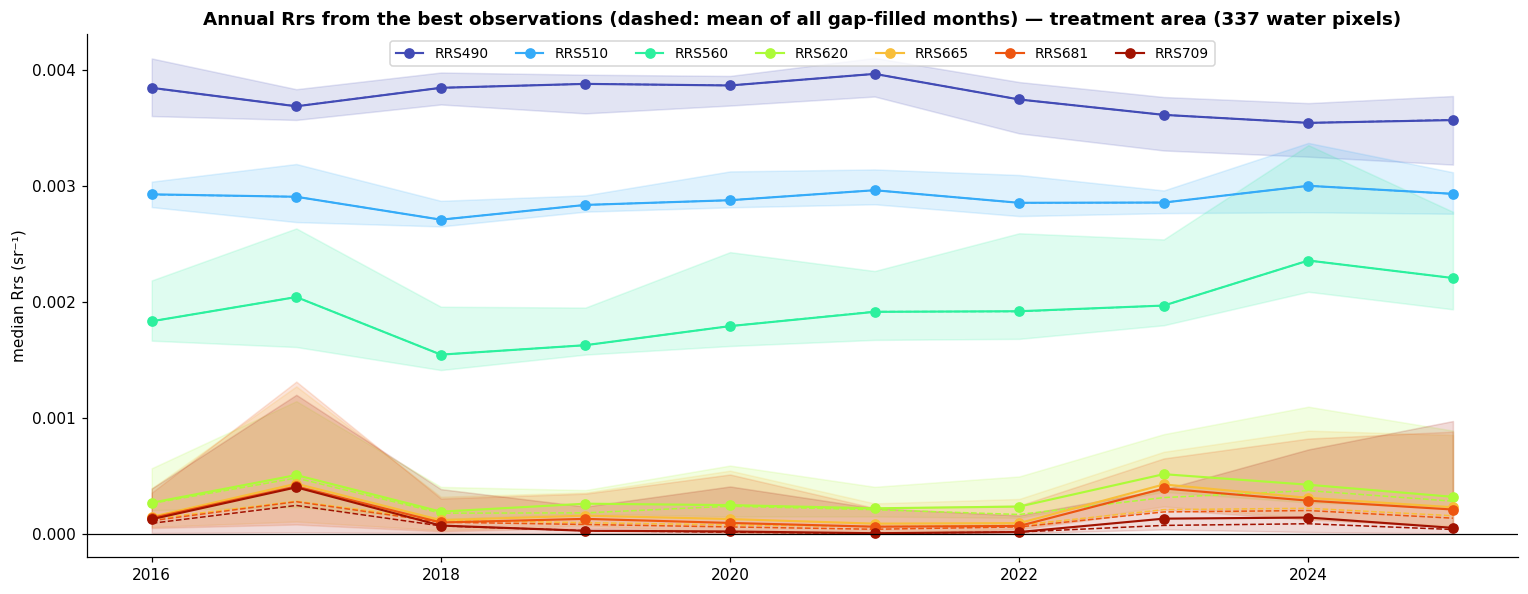

In [7]:
keep = ~cube.time.dt.strftime("%Y-%m").isin(list(EXCLUDE_MONTHS))
raw_k, gf_k = cube.sel(time=keep), cube_gf.sel(time=keep)
best = raw_k.where(raw_k >= 0)                                   # valid observations only

# annual composite: valid observations; gap-filled months only where a pixel-year has none
annual_bands = best.groupby("time.year").mean().fillna(gf_k.groupby("time.year").mean())
annual_bands_median = best.groupby("time.year").median().fillna(gf_k.groupby("time.year").median())

plot_rrs(annual_bands, "Annual Rrs from the best observations (dashed: mean of all gap-filled months)",
         dim="year", ref=gf_k.groupby("time.year").mean())

**Reading the figure.** Each solid line is the median, across the treatment pixels, of every pixel's annual value. The shaded band around it is the 25th–75th percentile across those pixels: it shows how much the water differs from place to place inside the treatment area in that year, not a measurement uncertainty and not the spread between months. A wide band means patchy water, for example near-shore pixels that differ strongly from the outer bay. The dashed line is the same median for the plain average of all twelve gap-filled months; where it sits below the solid line, the floor values had pulled that plain average down.

## 5 · S-3 indicator retrieval
**Diffuse attenuation, Kd490** — Mueller-type blue/green ratio polynomial (Rrs560 stands in for the canonical 555 nm), with $K_w = 0.0166$:
$$X=\log_{10}\frac{R_{rs}(490)}{R_{rs}(560)},\qquad K_d(490)=K_w+10^{\,a_0+a_1X+a_2X^2+a_3X^3+a_4X^4}$$

**Chlorophyll index, NDCI** (Mishra & Mishra 2012):
$$NDCI=\frac{R_{rs}(709)-R_{rs}(665)}{\left|R_{rs}(709)\right|+\left|R_{rs}(665)\right|}$$

**Turbidity, FTU** (Ouillon et al. 2008, three-band form):
$$T=245.59\left(\frac{R_{rs}(620)\,R_{rs}(681)}{R_{rs}(510)}\right)^{0.711}$$

All three indicators are computed from the annual band composites of step 4 (the mean composites; the median composites feed the median time series).

**How well does the Kd490 algorithm perform?** Our Kd490 formula is the NASA standard blue/green-ratio algorithm: a polynomial in log₁₀(Rrs490/Rrs555), plus the pure-water term Kw = 0.0166, with Rrs560 standing in for 555 nm on OLCI. A 2025 study in *Geo-spatial Information Science* evaluated it against Kd(490) matched to in-situ data from **NOMAD** and **BGC-Argo** floats, plus the modelled **IOCCG** dataset. Over 0.017–2.3 m⁻¹ it reaches **R² = 0.86, MAPE 11%, RMSE 0.099 m⁻¹, MAE 0.025 m⁻¹**.

![NASA Kd490 validation](https://raw.githubusercontent.com/Hauzero/Bridge-SpatialSustainableFinance/main/notebooks/images/kd490_nasa_validation.png)

*Validation of the NASA Kd(490) algorithm (panel "b NASA" of the study): retrieved vs. reference Kd(490), m⁻¹.*

Enhancing downwelling diffuse attenuation coefficient retrieval at 490 nm through a neural network and water classification system (2025). *Geo-spatial Information Science*. https://doi.org/10.1080/10095020.2025.2514177

**Validation of the turbidity algorithm.** Ouillon et al. (2008) calibrated turbidity algorithms against in-situ measurements in tropical coastal waters: 193 stations in New Caledonia, Cuba and Fiji. 

![Ouillon et al. 2008, Fig. 11b](https://raw.githubusercontent.com/Hauzero/Bridge-SpatialSustainableFinance/main/notebooks/images/ouillon2008_fig11b.png)

*Ouillon et al. (2008), Fig. 11b: turbidity against Rrs620·Rrs681/Rrs510 for 193 stations in New Caledonia (NC), Cuba and Fiji; fit Turb = 245.59 (Rrs620·Rrs681/Rrs510)^0.711, r² = 0.902.*

Ouillon, S., Douillet, P., Petrenko, A., Neveux, J., Dupouy, C., Froidefond, J.-M., Andréfouët, S., Muñoz-Caravaca, A. (2008). Optical algorithms at satellite wavelengths for total suspended matter in tropical coastal waters. *Sensors*, 8, 4165–4185.

In [8]:
KD490_COEF, KW = [-0.8353, -2.2298, 2.5066, 1.8107, -7.6979], 0.0166

def kd490(r490, r560):
    X = np.log10((r490 / r560).where((r490 > 0) & (r560 > 0)))
    a0, a1, a2, a3, a4 = KD490_COEF
    return KW + 10 ** (a0 + a1 * X + a2 * X**2 + a3 * X**3 + a4 * X**4)

def ndci(r709, r665):
    den = abs(r709) + abs(r665)
    return ((r709 - r665) / den).where(den > 1e-10)

def turbidity(r510, r620, r681):
    return 245.59 * (np.clip(r620 * r681, 0, None) / r510.where(abs(r510) >= 1e-9)) ** 0.711

def indicators(A):
    return xr.Dataset({
        "Kd490":     kd490(A.RRS490, A.RRS560),
        "NDCI":      ndci(A.RRS709, A.RRS665),
        "Turbidity": turbidity(A.RRS510, A.RRS620, A.RRS681),
    }).where(water)

annual_mean = indicators(annual_bands)
annual_median = indicators(annual_bands_median)

annual_mean.to_netcdf(OUT_DIR / "weda_indicators_annual_mean.nc")
annual_median.to_netcdf(OUT_DIR / "weda_indicators_annual_median.nc")
print("months per year:", keep.groupby("time.year").sum().to_series().to_dict())

months per year: {2016: 9, 2017: 12, 2018: 12, 2019: 12, 2020: 12, 2021: 12, 2022: 12, 2023: 12, 2024: 12, 2025: 12}


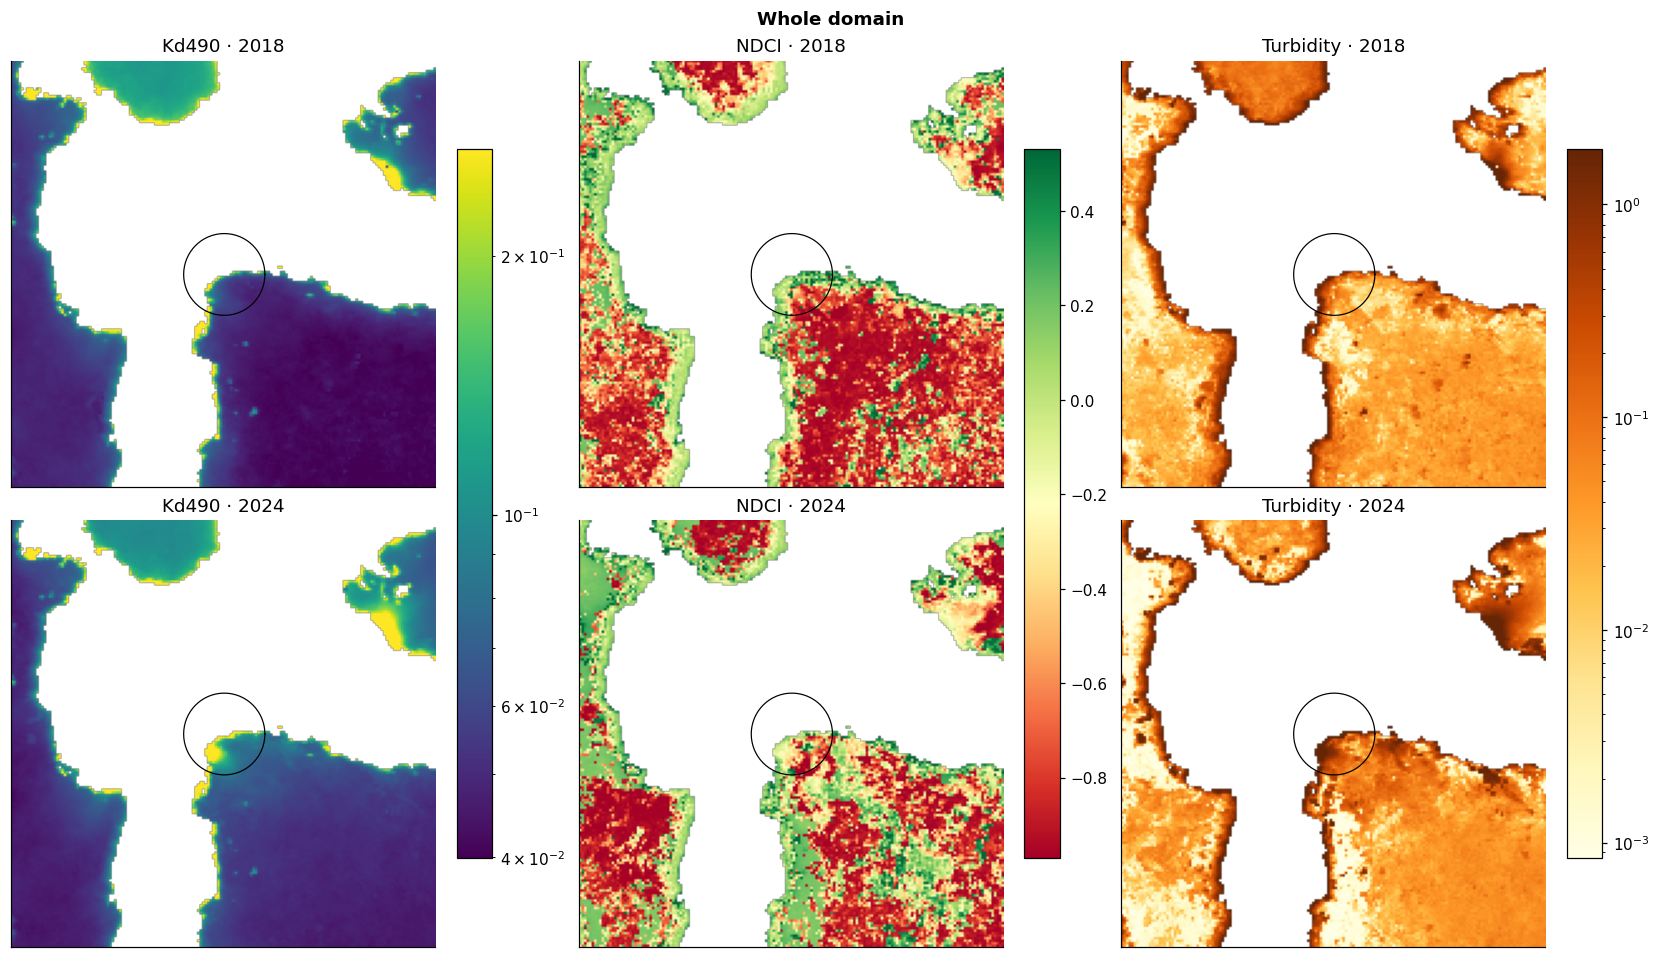

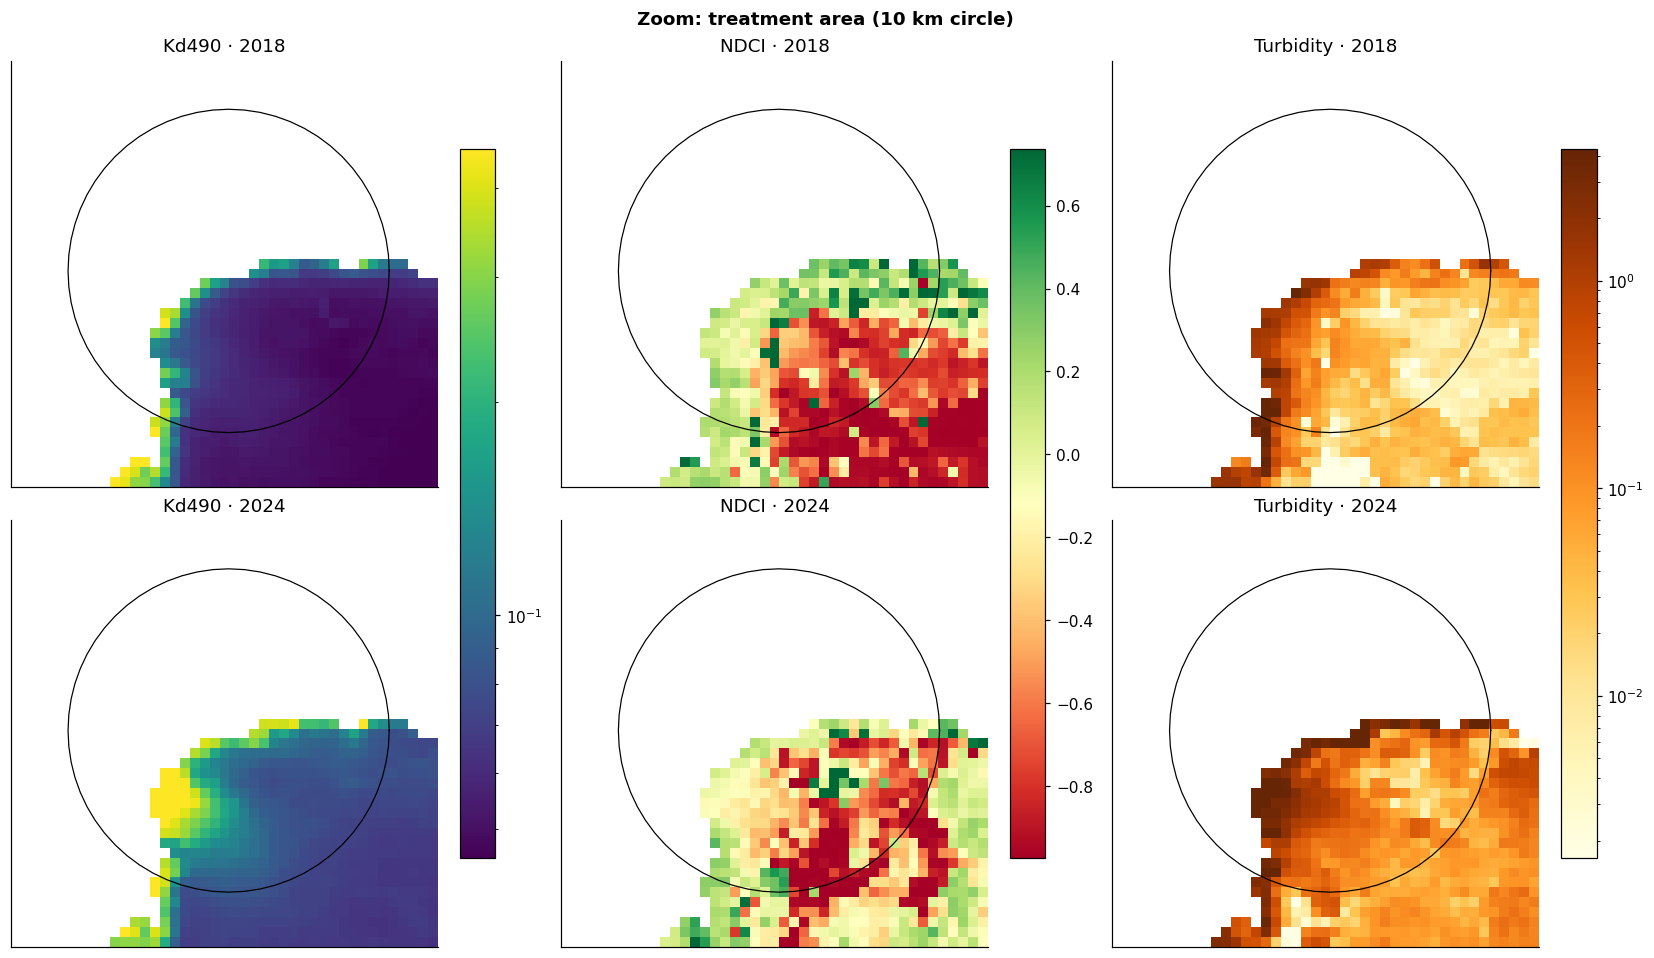

In [9]:
show_years = [2018, 2024]
cmaps = {"Kd490": "viridis", "NDCI": "RdYlGn", "Turbidity": "YlOrBr"}

def indicator_maps(bounds=None, title="Whole domain"):
    # bounds = (lon_min, lat_min, lon_max, lat_max) to zoom in; colour scales fit the area shown
    A = annual_mean.sel(year=show_years)
    if bounds is not None:
        A = A.sel(longitude=slice(bounds[0], bounds[2]), latitude=slice(bounds[3], bounds[1]))
    ext = [float(A.longitude.min()) - RES / 2, float(A.longitude.max()) + RES / 2,
           float(A.latitude.min()) - RES_Y / 2, float(A.latitude.max()) + RES_Y / 2]
    fig, axes = plt.subplots(len(show_years), 3, figsize=(15, 4.3 * len(show_years)), constrained_layout=True)
    for j, key in enumerate(cmaps):
        v = A[key].values[np.isfinite(A[key].values)]
        norm = Normalize(*np.percentile(v, [2, 98])) if key == "NDCI" else LogNorm(*np.percentile(v[v > 0], [2, 98]))
        for i, y in enumerate(show_years):
            ax = axes[i, j]
            im = ax.imshow(A[key].sel(year=y), extent=ext, cmap=cmaps[key], norm=norm)
            ax.plot(*mine_geom.exterior.xy, color="k", lw=0.8)
            ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
            ax.set_title(f"{key} · {y}"); ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=axes[:, j].tolist(), shrink=0.8)
    fig.suptitle(title, fontweight="bold")
    plt.show()

indicator_maps()

zpad = 0.03
zx0, zy0, zx1, zy1 = mine_geom.bounds
indicator_maps((zx0 - zpad, zy0 - zpad, zx1 + zpad, zy1 + zpad), "Zoom: treatment area (10 km circle)")

## 6 · Time-series plotter
Annual spatial mean ± 0.5σ over the treatment pixels (10 km circle). Background shading marks the baseline (2016–19), transition (2020–22) and recent (2023–25) blocks.

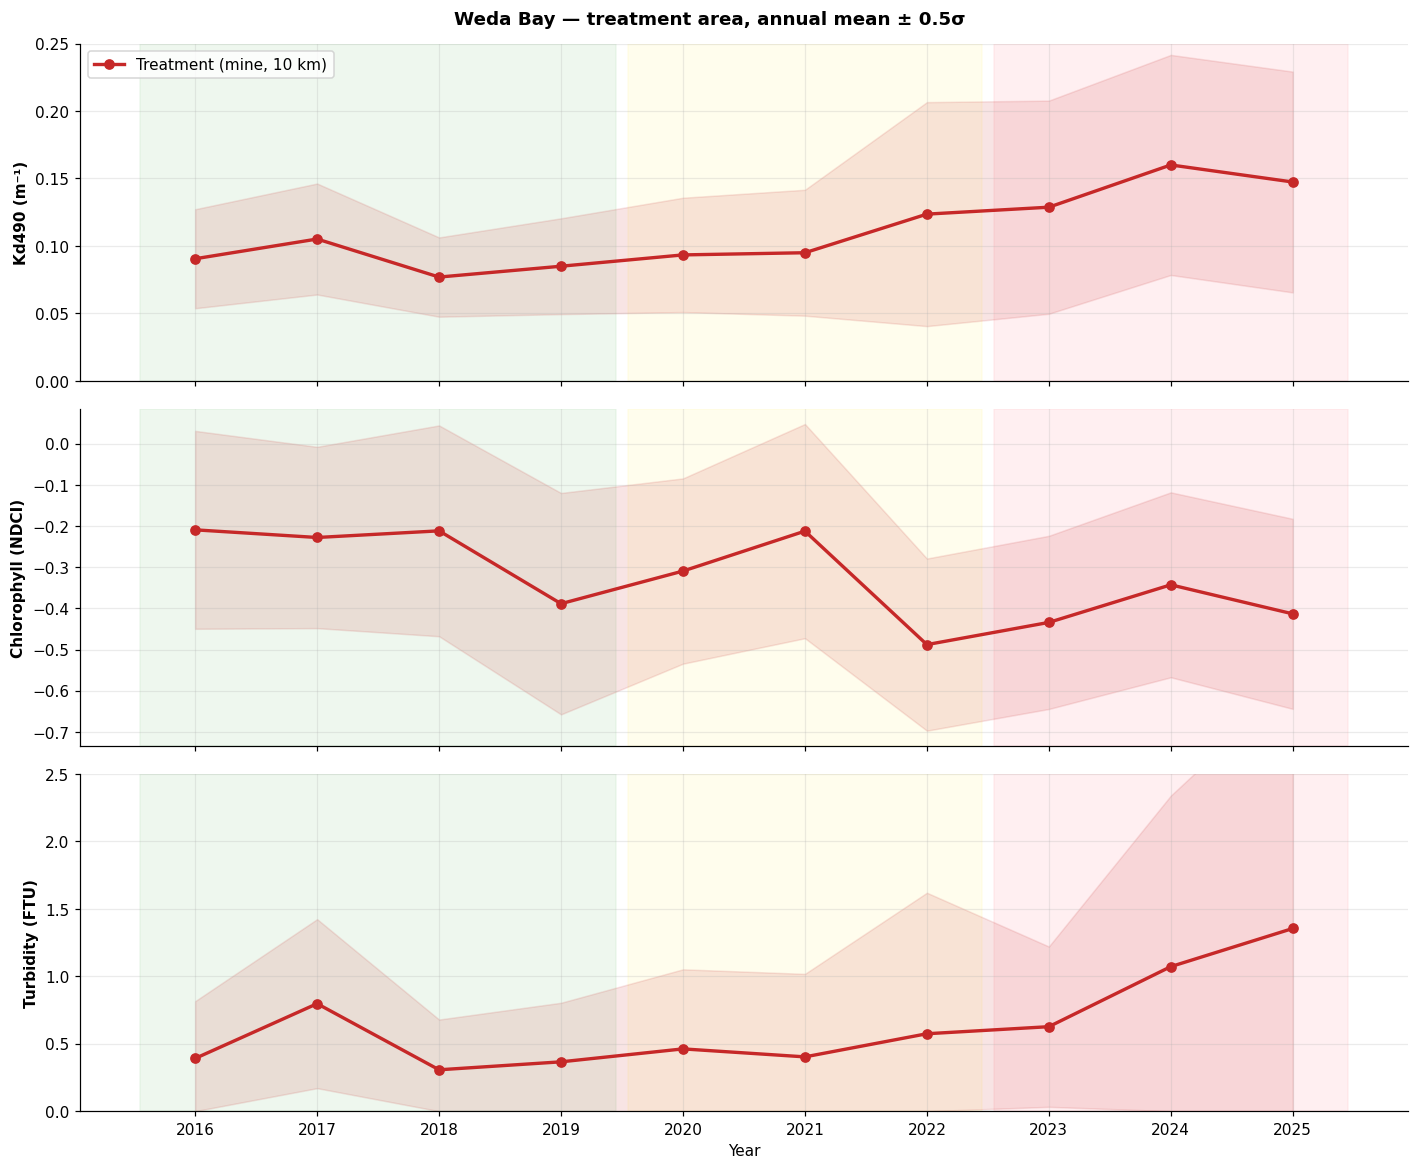

In [10]:
INDICATORS = [("Kd490", "Kd490 (m⁻¹)", dict(bottom=0, top=0.25), False),
              ("NDCI", "Chlorophyll (NDCI)", None, True),
              ("Turbidity", "Turbidity (FTU)", dict(bottom=0, top=2.5), False)]

def series(annual):
    rows = []
    for key, *_ in INDICATORS:
        t = annual[key].where(treat)
        rows.append(pd.DataFrame({"year": annual.year.values, "indicator": key,
                                  "mean": t.mean(["latitude", "longitude"]).values,
                                  "sd": t.std(["latitude", "longitude"]).values}))
    return pd.concat(rows, ignore_index=True)

def plot_timeseries(df, title):
    fig, axes = plt.subplots(len(INDICATORS), 1, figsize=(13, 3.6 * len(INDICATORS)), sharex=True)
    for ax, (key, label, ylim, signed) in zip(axes, INDICATORS):
        d = df[df.indicator == key]
        for _, b0, b1, col in BLOCKS:
            ax.axvspan(b0 - 0.45, b1 + 0.45, color=col, alpha=0.3, zorder=0)
        m, s = d["mean"].values, d["sd"].values
        ax.fill_between(d.year, np.maximum(m - 0.5 * s, -np.inf if signed else 0), m + 0.5 * s,
                        color="#c62828", alpha=0.12)
        ax.plot(d.year, m, marker="o", color="#c62828", lw=2.2, label="Treatment (mine, 10 km)")
        ax.set_ylabel(label, fontweight="bold"); ax.grid(alpha=0.25)
        if ylim:
            ax.set_ylim(**ylim)
    axes[0].legend(loc="upper left")
    axes[-1].set_xticks(df.year.unique()); axes[-1].set_xlabel("Year")
    fig.suptitle(title, fontweight="bold"); plt.tight_layout(); plt.show()

ts_mean = series(annual_mean)
ts_mean.to_csv(OUT_DIR / "weda_timeseries_annual_mean.csv", index=False)
plot_timeseries(ts_mean, "Weda Bay — treatment area, annual mean ± 0.5σ")

## Next steps
* **Find counterfactuals** — matched coastal control sites within the 50 km search area, to compare the treatment series against.
* **Validation?** — check the indicators against in-situ or independent data.
* **Add biodiversity?** — link the water-quality signal to biodiversity data (Dynamic Habitat Indicators; Biodiversity Intactness Index)
* Include **Terrestrial** Water Indicators: **Evapotranspiration, Canopy Moisture Content, Surface Water**
